# Assignment 2 – Airport security screening

Stochastic Simulation

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from scipy.stats import norm, truncnorm


## Part 1: System parameters from a peak month

### 1.1 Arrival rate per lane per minute

In [48]:
df = pd.read_csv("airport.csv")

# September data from 2015 to 2019 (pre-pandemic)
sept = df[(df["Month"] == "September") & (df["Year"].between(2015, 2019))]
avg_sept_passengers = sept["Total Passengers"].mean()

days = 30           # days in the month
hours_per_day = 16  # operational hours per day
n_lanes = 50        # number of security lanes

hourly_passengers = avg_sept_passengers / days / hours_per_day
lane_rate = hourly_passengers / n_lanes / 60   # passengers per lane per minute

part1_table = pd.DataFrame({
    "Quantity": ["Average September passengers (2015-2019)",
                 "Passengers per hour (all lanes)",
                 "Arrival rate per lane, lambda (pax/min)"],
    "Value": [round(avg_sept_passengers), round(hourly_passengers, 1), round(lane_rate, 4)]
})
print(sept[["Year", "Month", "Total Passengers"]].to_string(index=False))
print()
print(part1_table.to_string(index=False))

 Year     Month  Total Passengers
 2015 September           5466239
 2016 September           5866487
 2017 September           6259104
 2018 September           6396940
 2019 September           6493468

                                Quantity        Value
Average September passengers (2015-2019) 6096448.0000
         Passengers per hour (all lanes)   12700.9000
 Arrival rate per lane, lambda (pax/min)       4.2336


## Part 2: Discrete-event simulator

The simulator handles a FIFO queue with `servers` parallel servers (M/G/c).
Arrivals follow a Poisson process, so the time between two arrivals is exponential with mean 1/lambda.
Service times are normal and resampled when negative (truncated normal).
Each new passenger goes to the server that becomes free first.

In [49]:
def service_time(mean_B, sigma, rng):
    # draw from a normal distribution, resample if the value is negative
    x = rng.normal(mean_B, sigma)
    while x < 0:
        x = rng.normal(mean_B, sigma)
    return x

def discrete_event_simulator(lam, mean_B, sigma, servers, n_passengers, warmup=0, seed=None, by_completion=False):
    # lam = arrival rate (passengers per minute)
    # mean_B, sigma = mean and standard deviation of the service time (minutes)
    # servers = number of servers in the lane
    # n_passengers = number of passengers to simulate
    # warmup = number of first passengers that are discarded
    # seed = random seed, use a different one for every replication
    # by_completion = True: count passengers by when they finish service
    rng = np.random.default_rng(seed)

    # time at which each server becomes free, all servers are free at the start
    server_free_at = [0.0] * servers

    t = 0.0
    waits = []
    departures = []

    # include extra arrivals when counting completed passengers
    n_arrivals = n_passengers + servers - 1 if by_completion else n_passengers

    for i in range(n_arrivals):
        # next arrival: exponential interarrival time
        t = t + rng.exponential(1 / lam)

        # pick the server that is free first
        k = server_free_at.index(min(server_free_at))

        # service starts when the passenger has arrived and the server is free
        start = max(t, server_free_at[k])
        waits.append(start - t)

        # server is busy until the service is finished
        server_free_at[k] = start + service_time(mean_B, sigma, rng)
        departures.append(server_free_at[k])

    if by_completion:
        # keep the first n_passengers who finish service
        order = np.argsort(departures, kind="stable")[:n_passengers]
        waits = np.array(waits)[order]

    # return waiting times without the warm-up passengers
    return np.array(waits[warmup:])


def run_replications(R, lam, mean_B, sigma, servers, n_passengers, warmup=0, seed_offset=0, by_completion=False):
    # run R independent replications and return the mean waiting time of each one
    means = []
    for r in range(R):
        waits = discrete_event_simulator(lam, mean_B, sigma, servers, n_passengers,
                                         warmup=warmup, seed=seed_offset + r,
                                         by_completion=by_completion)
        means.append(waits.mean())
    return np.array(means)


def confidence_interval(data, alpha=0.05):
    # t-based confidence interval for the mean of the data
    n = len(data)
    mean = data.mean()
    half_width = stats.t.ppf(1 - alpha / 2, df=n - 1) * data.std(ddof=1) / np.sqrt(n)
    return mean - half_width, mean + half_width

## Part 2A: Validating the simulator

We test the simulator on a stable M/G/1 system with target utilization rho = 0.85
and compare the simulated mean waiting time with the Pollaczek-Khintchine (P-K) formula.

In [50]:
# parameters
mean_B = 1.0
sigma = 0.25
rho_target = 0.85
R = 40
warmup = 1000
n_passengers = 51000   # 1000 warm-up passengers + 50000 passengers in steady state
alpha = 0.05

# step 1: stable test rate
lam_test = rho_target / mean_B
rho_test = lam_test * mean_B
print("lambda_test =", lam_test, "pax/min")
print("rho_test =", rho_test, "-> stable:", rho_test < 1)

# step 2: theoretical waiting time with the P-K formula
ES2 = mean_B**2 + sigma**2
Wq_theory = lam_test * ES2 / (2 * (1 - rho_test))
print("Wq_theory =", round(Wq_theory, 4), "min")

lambda_test = 0.85 pax/min
rho_test = 0.85 -> stable: True
Wq_theory = 3.0104 min


In [51]:
# step 3: simulation with R independent replications
Wq_reps = run_replications(R, lam_test, mean_B, sigma, servers=1,
                           n_passengers=n_passengers, warmup=warmup)
Wq_sim = Wq_reps.mean()
ci_low, ci_high = confidence_interval(Wq_reps, alpha)

# step 4: one-sample t-test
# H0: the expected simulated waiting time equals Wq_theory
# H1: the expected simulated waiting time differs from Wq_theory
t_stat, p_value = stats.ttest_1samp(Wq_reps, Wq_theory)

results_2a = pd.DataFrame({
    "Quantity": ["lambda_test (pax/min)", "rho_test", "E[S^2]", "Wq theory (min)",
                 "Wq simulation (min)", "Std over replications", "95% CI lower",
                 "95% CI upper", "t-statistic", "p-value"],
    "Value": [lam_test, rho_test, ES2, Wq_theory, Wq_sim, Wq_reps.std(ddof=1),
              ci_low, ci_high, t_stat, p_value]
}).round(4)
print(results_2a.to_string(index=False))
print()

if p_value < alpha:
    print("H0 is rejected: the simulator differs significantly from the theory.")
else:
    print("H0 is not rejected: no significant difference, the simulator validates.")

             Quantity   Value
lambda_test (pax/min)  0.8500
             rho_test  0.8500
               E[S^2]  1.0625
      Wq theory (min)  3.0104
  Wq simulation (min)  2.9969
Std over replications  0.1342
         95% CI lower  2.9539
         95% CI upper  3.0398
          t-statistic -0.6391
              p-value  0.5265

H0 is not rejected: no significant difference, the simulator validates.


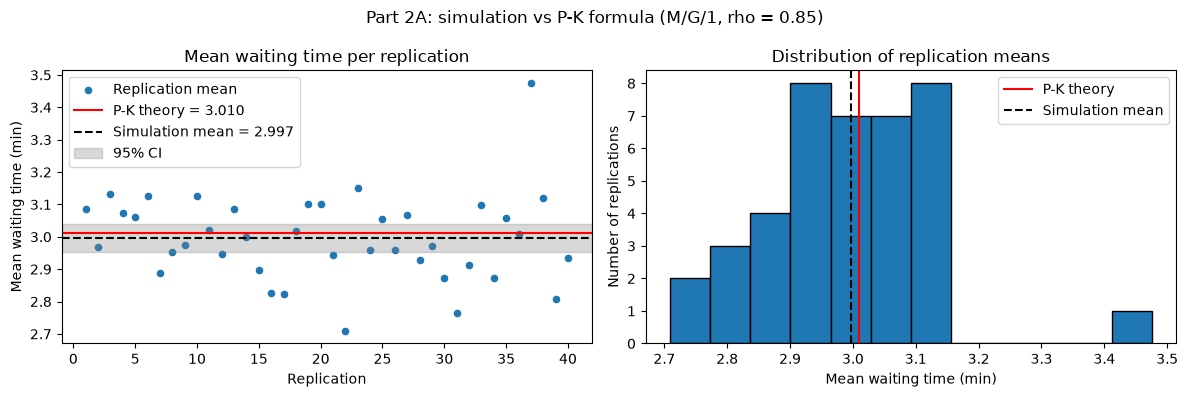

In [52]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: mean waiting time per replication with the CI and the theoretical value
axes[0].scatter(range(1, R + 1), Wq_reps, s=20, label="Replication mean")
axes[0].axhline(Wq_theory, color="red", label=f"P-K theory = {Wq_theory:.3f}")
axes[0].axhline(Wq_sim, color="black", linestyle="--", label=f"Simulation mean = {Wq_sim:.3f}")
axes[0].axhspan(ci_low, ci_high, color="gray", alpha=0.3, label="95% CI")
axes[0].set_xlabel("Replication")
axes[0].set_ylabel("Mean waiting time (min)")
axes[0].set_title("Mean waiting time per replication")
axes[0].legend()

# right: distribution of the replication means
axes[1].hist(Wq_reps, bins=12, edgecolor="black")
axes[1].axvline(Wq_theory, color="red", label="P-K theory")
axes[1].axvline(Wq_sim, color="black", linestyle="--", label="Simulation mean")
axes[1].set_xlabel("Mean waiting time (min)")
axes[1].set_ylabel("Number of replications")
axes[1].set_title("Distribution of replication means")
axes[1].legend()

fig.suptitle("Part 2A: simulation vs P-K formula (M/G/1, rho = 0.85)")
plt.tight_layout()
plt.show()

## Part 2B: Evaluating interventions

Each scenario uses the arrival rate from Part 1 and simulates 3000 passengers without warm-up,
with R = 40 replications. The metric is the mean waiting time of all 3000 passengers.

In [53]:
n_passengers_2b = 3000
R = 40
alpha = 0.05

scenarios = {
    "Baseline": {"servers": 1, "sigma": 0.25, "mean_B": 1.0},
    "Option A": {"servers": 2, "sigma": 0.25, "mean_B": 1.0},
    "Option B": {"servers": 1, "sigma": 0.10, "mean_B": 1.0},
}

# run all scenarios, each scenario gets its own seeds so the samples are independent
results_2b = {}
for i, (name, par) in enumerate(scenarios.items()):
    results_2b[name] = run_replications(R, lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                        n_passengers=n_passengers_2b, seed_offset=1000 * (i + 1))

# summary table per scenario
rows = []
for name, par in scenarios.items():
    data = results_2b[name]
    low, high = confidence_interval(data, alpha)
    rows.append({
        "Scenario": name,
        "Servers": par["servers"],
        "sigma (min)": par["sigma"],
        "rho": round(lane_rate * par["mean_B"] / par["servers"], 3),
        "Mean Wq (min)": round(data.mean(), 2),
        "Std (min)": round(data.std(ddof=1), 2),
        "95% CI lower": round(low, 2),
        "95% CI upper": round(high, 2),
    })
summary_2b = pd.DataFrame(rows)
print(summary_2b.to_string(index=False))

Scenario  Servers  sigma (min)   rho  Mean Wq (min)  Std (min)  95% CI lower  95% CI upper
Baseline        1         0.25 4.234        1142.49      10.37       1139.18       1145.81
Option A        2         0.25 2.117         392.86       7.94        390.33        395.40
Option B        1         0.10 4.234        1145.59       8.86       1142.75       1148.42


In [54]:
# Welch two-sample t-tests, one-sided
# H0: the option has the same mean waiting time as the baseline
# H1: the option has a lower mean waiting time than the baseline
# we do two tests, so we also report the Bonferroni corrected significance level
alpha_bonf = alpha / 2

rows = []
for option in ["Option A", "Option B"]:
    t_stat, p_value = stats.ttest_ind(results_2b["Baseline"], results_2b[option],
                                      equal_var=False, alternative="greater")
    rows.append({
        "Comparison": f"Baseline vs {option}",
        "Mean difference (min)": round(results_2b["Baseline"].mean() - results_2b[option].mean(), 2),
        "t-statistic": round(t_stat, 3),
        "p-value": p_value,
        "Significant (alpha = 0.05)": p_value < alpha,
        "Significant (Bonferroni, 0.025)": p_value < alpha_bonf,
    })
tests_2b = pd.DataFrame(rows)
print(tests_2b.to_string(index=False))

          Comparison  Mean difference (min)  t-statistic       p-value  Significant (alpha = 0.05)  Significant (Bonferroni, 0.025)
Baseline vs Option A                 749.63      363.111 5.454504e-121                        True                             True
Baseline vs Option B                  -3.10       -1.435  9.223738e-01                       False                            False


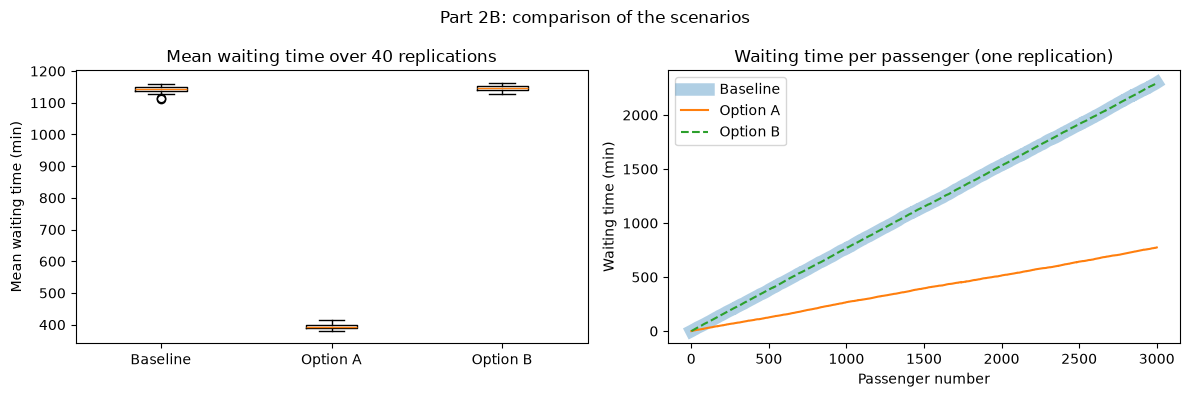

In [55]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: boxplot of the replication means per scenario
names = list(scenarios.keys())
axes[0].boxplot([results_2b[name] for name in names])
axes[0].set_xticks(range(1, len(names) + 1))
axes[0].set_xticklabels(names)
axes[0].set_ylabel("Mean waiting time (min)")
axes[0].set_title("Mean waiting time over 40 replications")

# right: waiting time per passenger for one replication of each scenario
# Option B lies exactly on the baseline, so the baseline is drawn as a wide, light band
# and Option B as a thin dashed line on top of it
line_style = {
    "Baseline": {"color": "C0", "linestyle": "-", "linewidth": 9, "alpha": 0.35, "zorder": 1},
    "Option A": {"color": "C1", "linestyle": "-", "linewidth": 1.5, "zorder": 2},
    "Option B": {"color": "C2", "linestyle": "--", "linewidth": 1.5, "zorder": 3},
}
for i, (name, par) in enumerate(scenarios.items()):
    waits = discrete_event_simulator(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                     n_passengers_2b, seed=1000 * (i + 1))
    axes[1].plot(range(1, n_passengers_2b + 1), waits, label=name, **line_style[name])
axes[1].set_xlabel("Passenger number")
axes[1].set_ylabel("Waiting time (min)")
axes[1].set_title("Waiting time per passenger (one replication)")
axes[1].legend()

fig.suptitle("Part 2B: comparison of the scenarios")
plt.tight_layout()
plt.show()


## Extra figures

`simulate_times` is a copy of the simulator that also returns arrival and service start times (needed for the queue length in Figure 3). It draws the random numbers in the same order, so the same seed gives the same passengers.

In [56]:


# colours and line styles per scenario, the same as in the Part 2B figure
style = {
    "Baseline": {"color": "C0", "linestyle": "-"},
    "Option A": {"color": "C1", "linestyle": "-"},
    "Option B": {"color": "C2", "linestyle": "--"},
}

### Figure 1: transient behaviour vs fluid approximation

For rho > 1 every passenger adds on average E[B]/c − 1/lambda minutes to the wait of the next one, so W_n ≈ (n−1)(E[B]/c − 1/lambda). The variance of the service time does not appear in this slope, which explains why Option B has no effect.

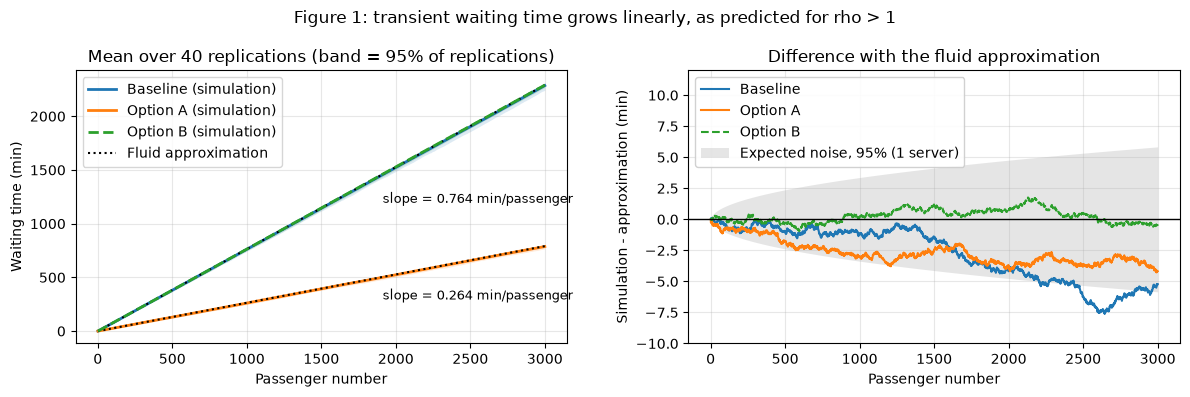

In [57]:
# Figure 1: waiting time per passenger, simulation vs fluid approximation
# for rho > 1 the queue grows with a fixed amount per passenger:
#   W_n ~ (n - 1) * (E[B] / c - 1 / lambda)
n_idx = np.arange(1, n_passengers_2b + 1)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for i, (name, par) in enumerate(scenarios.items()):
    # all 40 replications, same seeds as in Part 2B
    waits = np.array([discrete_event_simulator(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                               n_passengers_2b, seed=1000 * (i + 1) + r)
                      for r in range(R)])
    mean_w = waits.mean(axis=0)
    lo, hi = np.percentile(waits, [2.5, 97.5], axis=0)
    slope = par["mean_B"] / par["servers"] - 1 / lane_rate
    theory = (n_idx - 1) * slope

    axes[0].fill_between(n_idx, lo, hi, color=style[name]["color"], alpha=0.15, linewidth=0)
    axes[0].plot(n_idx, mean_w, linewidth=2, label=f"{name} (simulation)", **style[name])
    axes[1].plot(n_idx, mean_w - theory, linewidth=1.5, label=name, **style[name])
    if name != "Option B":   # Option B has the same theory line as the baseline
        axes[0].plot(n_idx, theory, color="black", linestyle=":", linewidth=1.5)
        axes[0].annotate(f"slope = {slope:.3f} min/passenger", xy=(n_idx[-1] * 0.6, theory[-1] * 0.6),
                         xytext=(12, -14), textcoords="offset points", ha="left", fontsize=9)

axes[0].plot([], [], color="black", linestyle=":", label="Fluid approximation")
axes[0].set_xlabel("Passenger number")
axes[0].set_ylabel("Waiting time (min)")
axes[0].set_title("Mean over 40 replications (band = 95% of replications)")
axes[0].legend()
axes[0].grid(alpha=0.3)

# expected noise of a mean over R replications for one server: each passenger adds an
# increment S - A with variance sigma^2 + 1/lambda^2, so the sd after n passengers grows with sqrt(n)
noise = 1.96 * np.sqrt((n_idx - 1) * (0.25**2 + 1 / lane_rate**2) / R)
axes[1].fill_between(n_idx, -noise, noise, color="gray", alpha=0.2, linewidth=0,
                     label="Expected noise, 95% (1 server)")
axes[1].axhline(0, color="black", linewidth=1)
axes[1].set_xlabel("Passenger number")
axes[1].set_ylabel("Simulation - approximation (min)")
axes[1].set_title("Difference with the fluid approximation")
axes[1].set_ylim(-10, 12)
axes[1].legend(loc="upper left", framealpha=0.9)
axes[1].grid(alpha=0.3)

fig.suptitle("Figure 1: transient waiting time grows linearly, as predicted for rho > 1")
plt.tight_layout()
plt.show()

### Figure 2: waiting time against the number of servers

Sweep over c = 1…6 servers in one lane, for sigma = 0.25 and sigma = 0.10. The system becomes stable from c = 5 (rho = 0.85).

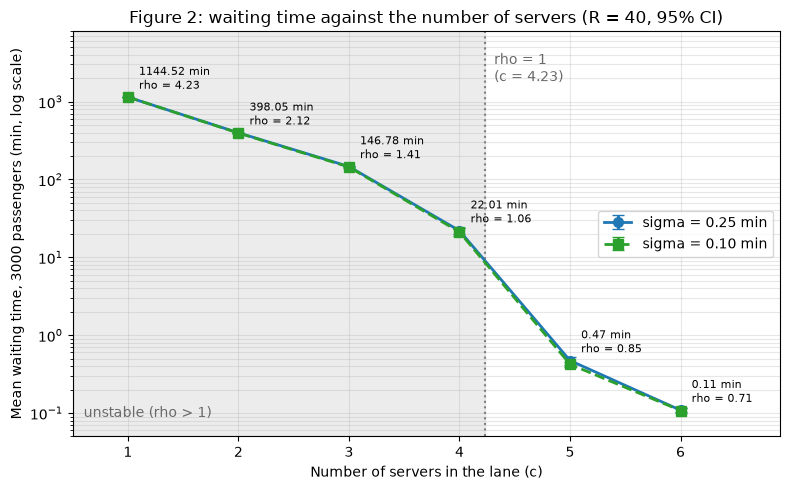

 sigma  servers   rho     mean      low     high
  0.25        1 4.234 1144.515 1141.458 1147.573
  0.25        2 2.117  398.047  395.792  400.302
  0.25        3 1.411  146.783  144.124  149.442
  0.25        4 1.058   22.005   19.879   24.131
  0.25        5 0.847    0.473    0.413    0.532
  0.25        6 0.706    0.109    0.103    0.115
  0.10        1 4.234 1144.559 1141.689 1147.430
  0.10        2 2.117  395.128  392.573  397.683
  0.10        3 1.411  144.711  142.369  147.054
  0.10        4 1.058   21.154   18.721   23.586
  0.10        5 0.847    0.423    0.396    0.451
  0.10        6 0.706    0.108    0.101    0.115


In [58]:
# Figure 2: mean waiting time against the number of servers in one lane
server_range = range(1, 7)
sigmas = {0.25: {"color": "C0", "marker": "o", "linestyle": "-"},
          0.10: {"color": "C2", "marker": "s", "linestyle": "--"}}

rows = []
for j, (sig, st) in enumerate(sigmas.items()):
    for c in server_range:
        data = run_replications(R, lane_rate, 1.0, sig, c, n_passengers=n_passengers_2b,
                                seed_offset=10000 + 1000 * j + 100 * c)
        low, high = confidence_interval(data, alpha)
        rows.append({"sigma": sig, "servers": c, "rho": lane_rate * 1.0 / c,
                     "mean": data.mean(), "low": low, "high": high})
sweep = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 5))
c_critical = lane_rate * 1.0   # rho = 1 when c = lambda * E[B]
ax.axvspan(0.5, c_critical, color="gray", alpha=0.15)
ax.axvline(c_critical, color="gray", linestyle=":")
ax.text(c_critical + 0.08, 0.95, f"rho = 1\n(c = {c_critical:.2f})", ha="left", va="top",
        transform=ax.get_xaxis_transform(), color="dimgray")
ax.text(0.6, 0.04, "unstable (rho > 1)", transform=ax.get_xaxis_transform(), va="bottom", color="dimgray")

for sig, st in sigmas.items():
    d = sweep[sweep["sigma"] == sig]
    err = np.vstack([d["mean"] - d["low"], d["high"] - d["mean"]])
    ax.errorbar(d["servers"], d["mean"], yerr=err, capsize=4, markersize=7, linewidth=2,
                label=f"sigma = {sig:.2f} min", **st)

# value and rho labels for the sigma = 0.25 line
for _, row in sweep[sweep["sigma"] == 0.25].iterrows():
    ax.annotate(f"{row['mean']:.2f} min\nrho = {row['rho']:.2f}",
                xy=(row["servers"], row["mean"]), xytext=(8, 6), textcoords="offset points", fontsize=8)

ax.set_yscale("log")
ax.set_ylim(0.05, 8000)
ax.set_xticks(list(server_range))
ax.set_xlim(0.5, 6.9)
ax.set_xlabel("Number of servers in the lane (c)")
ax.set_ylabel("Mean waiting time, 3000 passengers (min, log scale)")
ax.set_title("Figure 2: waiting time against the number of servers (R = 40, 95% CI)")
ax.legend(loc="center right")
ax.grid(alpha=0.3, which="both")
plt.tight_layout()
plt.show()

print(sweep.round(3).to_string(index=False))

### Figure 3: queue length over the day

Number of people waiting (not yet in service) against clock time. The plot stops at the earliest last arrival over all replications, because after that no new passengers enter the model.

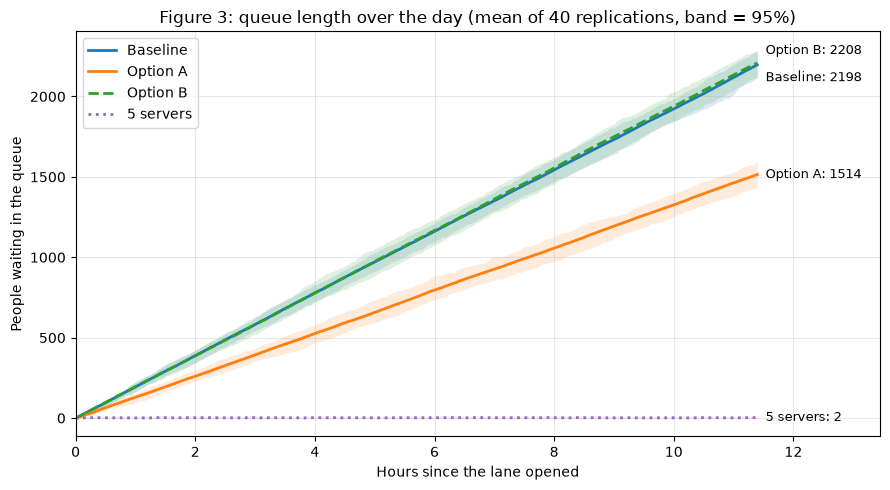

In [59]:
# Figure 3: number of people waiting in the queue over the day
extra = {"5 servers": {"servers": 5, "sigma": 0.25, "mean_B": 1.0}}
all_scen = {**scenarios, **extra}
style["5 servers"] = {"color": "C4", "linestyle": ":"}

label_offset = {"Baseline": -9, "Option A": 0, "Option B": 9, "5 servers": 0}   # points, avoids overlap

sims = {}
for i, (name, par) in enumerate(all_scen.items()):
    sims[name] = [simulate_times(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                 n_passengers_2b, seed=1000 * (i + 1) + r) for r in range(R)]

# only plot up to the earliest last arrival: after that no new passengers enter the model
# and the queue would shrink artificially
t_end = min(arr[-1] for runs in sims.values() for arr, _, _ in runs)
grid = np.linspace(0, t_end, 600)

fig, ax = plt.subplots(figsize=(9, 5))
for name, runs in sims.items():
    # people in queue at time t = arrived by t - started service by t
    q = np.array([np.searchsorted(arr, grid, side="right") - np.searchsorted(start, grid, side="right")
                  for arr, start, _ in runs])
    mean_q = q.mean(axis=0)
    lo, hi = np.percentile(q, [2.5, 97.5], axis=0)
    ax.fill_between(grid / 60, lo, hi, color=style[name]["color"], alpha=0.15, linewidth=0)
    ax.plot(grid / 60, mean_q, linewidth=2, label=name, **style[name])
    # direct label at the end of the line
    ax.annotate(f"{name}: {mean_q[-1]:.0f}", xy=(grid[-1] / 60, mean_q[-1]),
                xytext=(6, label_offset[name]), textcoords="offset points", va="center", fontsize=9)

ax.set_xlim(0, t_end / 60 * 1.18)
ax.set_xlabel("Hours since the lane opened")
ax.set_ylabel("People waiting in the queue")
ax.set_title("Figure 3: queue length over the day (mean of 40 replications, band = 95%)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### A1. Derived quantities from Part 1

In [60]:
lam = lane_rate
print(f"lambda per lane            = {lam:.4f} pax/min, mean interarrival time 1/lambda = {1/lam:.4f} min")
print(f"time until 3000 arrivals   = n/lambda = {3000/lam:.1f} min = {3000/lam/60:.2f} h (fits in a 16 h day)")
for c in [1, 2]:
    print(f"c = {c}: rho = lambda*E[B]/c = {lam*1.0/c:.3f}  -> unstable")
c_min = int(np.floor(lam * 1.0)) + 1
print(f"stability needs c > lambda*E[B] = {lam:.3f}, so at least c = {c_min} servers per lane (rho = {lam/c_min:.3f})")
print(f"hypothetical pooled airport: lambda_total = {lam*n_lanes:.1f} pax/min, so at least {int(np.floor(lam*n_lanes))+1} servers are needed (today {n_lanes})")
print(f"one server per lane would need E[B] < 1/lambda = {1/lam:.3f} min = {60/lam:.1f} s per passenger")

lambda per lane            = 4.2336 pax/min, mean interarrival time 1/lambda = 0.2362 min
time until 3000 arrivals   = n/lambda = 708.6 min = 11.81 h (fits in a 16 h day)
c = 1: rho = lambda*E[B]/c = 4.234  -> unstable
c = 2: rho = lambda*E[B]/c = 2.117  -> unstable
stability needs c > lambda*E[B] = 4.234, so at least c = 5 servers per lane (rho = 0.847)
hypothetical pooled airport: lambda_total = 211.7 pax/min, so at least 212 servers are needed (today 50)
one server per lane would need E[B] < 1/lambda = 0.236 min = 14.2 s per passenger


### A2. The truncated normal service time

In [61]:
rows = []
for sig in [0.25, 0.10]:
    a = (0 - 1.0) / sig                      # truncation point in standard units
    tn = truncnorm(a, np.inf, loc=1.0, scale=sig)
    rows.append({"sigma": sig, "P(B < 0)": norm.cdf(a),
                 "E[B] truncated": tn.mean(), "Var(B) truncated": tn.var(), "sigma^2": sig**2,
                 "E[S^2] = E[B]^2 + sigma^2": 1.0 + sig**2})
trunc_table = pd.DataFrame(rows)
print(trunc_table.to_string(index=False, float_format=lambda x: f"{x:.6g}"))

 sigma    P(B < 0)  E[B] truncated  Var(B) truncated  sigma^2  E[S^2] = E[B]^2 + sigma^2
  0.25 3.16712e-05         1.00003         0.0624665   0.0625                     1.0625
   0.1 7.61985e-24               1              0.01     0.01                       1.01


### A3. Part 2A: assumptions of the t-test, non-parametric check and power

In [62]:
shapiro_2a = stats.shapiro(Wq_reps)                      # H0: the replication means are normal
wilcoxon_2a = stats.wilcoxon(Wq_reps - Wq_theory)        # H0: median of the replication means = Wq_theory
Lq_theory = lam_test * Wq_theory                         # Little's law for the queue
z_a, z_b = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(0.90)
s_2a = Wq_reps.std(ddof=1)
delta_min_2a = (z_a + z_b) * s_2a / np.sqrt(R)           # smallest difference R = 40 detects with power 0.9
t_crit_2a = stats.t.ppf(1 - alpha / 2, df=R - 1)

checks_2a = pd.DataFrame({
    "Quantity": ["Shapiro-Wilk p (normality of 40 means)", "Wilcoxon signed-rank p",
                 "t critical value t(0.975, 39)", "Lq theory = lambda*Wq (pax)",
                 "Sample sd of replication means s", "Detectable difference, power 0.9 (min)",
                 "Detectable difference as % of Wq"],
    "Value": [shapiro_2a.pvalue, wilcoxon_2a.pvalue, t_crit_2a, Lq_theory, s_2a,
              delta_min_2a, 100 * delta_min_2a / Wq_theory]}).round(4)
print(checks_2a.to_string(index=False))

                              Quantity  Value
Shapiro-Wilk p (normality of 40 means) 0.0254
                Wilcoxon signed-rank p 0.4598
         t critical value t(0.975, 39) 2.0227
           Lq theory = lambda*Wq (pax) 2.5589
      Sample sd of replication means s 0.1342
Detectable difference, power 0.9 (min) 0.0688
      Detectable difference as % of Wq 2.2846


### A4. Part 2B: fluid (random-walk) approximation

For sustained overload, a rough leading-order drift per arriving customer is `d = E[B]/c - 1/lambda`. This is a fluid approximation (particularly for `c>1`), not the exact expected waiting time of an individual passenger. For a single server the reflected Lindley recursion provides the random-walk connection. Comparisons below use first 3,000 completions and are approximate.


In [63]:
n = n_passengers_2b
var_factor = (n - 1) * (2 * n - 1) / (6 * n)          # sum_{k=1}^{n-1} (n-k)^2 / n^2
rows = []
for name, par in scenarios.items():
    d = par["mean_B"] / par["servers"] - 1 / lane_rate
    data = results_2b[name]
    sd_pred = np.sqrt((par["sigma"]**2 + 1 / lane_rate**2) * var_factor) if par["servers"] == 1 else np.nan
    rows.append({"Scenario": name, "rho": lane_rate * par["mean_B"] / par["servers"], "slope d (min/pax)": d,
                 "Fluid mean (n-1)d/2": (n - 1) * d / 2, "Simulated mean": data.mean(),
                 "Difference %": 100 * (data.mean() - (n - 1) * d / 2) / ((n - 1) * d / 2),
                 "Predicted sd (c=1)": sd_pred, "Simulated sd": data.std(ddof=1)})
fluid_table = pd.DataFrame(rows).round(3)
print(fluid_table.to_string(index=False))

Scenario   rho  slope d (min/pax)  Fluid mean (n-1)d/2  Simulated mean  Difference %  Predicted sd (c=1)  Simulated sd
Baseline 4.234              0.764             1145.313        1142.491        -0.246              10.873        10.366
Option A 2.117              0.264              395.563         392.865        -0.682                 NaN         7.938
Option B 4.234              0.764             1145.313        1145.586         0.024               8.109         8.860


### A5. Part 2B: assumptions, direct comparison of A and B, rank-based tests

In [64]:
print("Shapiro-Wilk p-values (normality of the 40 replication means):")
for name in scenarios:
    print(f"  {name}: {stats.shapiro(results_2b[name]).pvalue:.3f}")

rows = []
for a, b, alt in [("Baseline", "Option A", "greater"), ("Baseline", "Option B", "greater"),
                  ("Option B", "Option A", "greater")]:
    x, y = results_2b[a], results_2b[b]
    w = stats.ttest_ind(x, y, equal_var=False, alternative=alt)
    vx, vy = x.var(ddof=1) / len(x), y.var(ddof=1) / len(y)
    df_ws = (vx + vy)**2 / (vx**2 / (len(x) - 1) + vy**2 / (len(y) - 1))   # Welch-Satterthwaite
    mw = stats.mannwhitneyu(x, y, alternative=alt)                         # Wilcoxon rank-sum
    rows.append({"H1": f"mean({b}) < mean({a})", "difference (min)": x.mean() - y.mean(),
                 "Welch t": w.statistic, "df": df_ws, "Welch p": w.pvalue, "rank-sum p": mw.pvalue})
tests_extra = pd.DataFrame(rows)
print(tests_extra.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

Shapiro-Wilk p-values (normality of the 40 replication means):
  Baseline: 0.020
  Option A: 0.339
  Option B: 0.727
                             H1  difference (min)  Welch t    df    Welch p  rank-sum p
mean(Option A) < mean(Baseline)             749.6    363.1 73.04 5.455e-121   7.175e-15
mean(Option B) < mean(Baseline)            -3.095   -1.435 76.15     0.9224      0.8845
mean(Option A) < mean(Option B)             752.7    400.2 77.08 6.176e-130   7.175e-15


### A6. Common random numbers: Baseline vs Option B

To compare two scenarios on the same randomness, each passenger gets one exponential interarrival time and one
uniform number U. The service time is made by inverse transform from the truncated normal,
B = E[B] + sigma * PhiInv(Phi(a) + U (1 - Phi(a))) with a = -E[B]/sigma, so both scenarios see exactly the same passengers
and only sigma differs. This is the variance-reduction idea Var(X - Y) = Var(X) + Var(Y) - 2 Cov(X, Y).

In [65]:
def waits_from_inputs(interarrival, service, servers, n_completions=None):
    # same FIFO logic as discrete_event_simulator, but with given inputs
    server_free_at = [0.0] * servers
    t, waits = 0.0, np.empty(len(interarrival))
    departures = np.empty(len(interarrival))
    for i in range(len(interarrival)):
        t += interarrival[i]
        k = server_free_at.index(min(server_free_at))
        start = max(t, server_free_at[k])
        waits[i] = start - t
        server_free_at[k] = start + service[i]
        departures[i] = server_free_at[k]
    if n_completions is not None:
        return waits[np.argsort(departures, kind="stable")[:n_completions]]
    return waits


def truncnorm_inverse(u, mean_B, sigma):
    # inverse transform for the normal distribution truncated at 0
    a = norm.cdf(-mean_B / sigma)
    return mean_B + sigma * norm.ppf(a + u * (1 - a))


def crn_pair(lam, servers, sigma_1, sigma_2, n_pax, R, warmup=0, seed_offset=0, mean_B=1.0):
    # R replications; replication r gives both scenarios the same arrivals and the same U's
    m1, m2 = [], []
    for r in range(R):
        rng = np.random.default_rng(seed_offset + r)
        n_draws = n_pax + (servers - 1 if warmup == 0 else 0)
        inter = rng.exponential(1 / lam, n_draws)
        u = rng.random(n_draws)
        n_complete = n_pax if warmup == 0 else None
        m1.append(waits_from_inputs(inter, truncnorm_inverse(u, mean_B, sigma_1), servers, n_complete)[warmup:].mean())
        m2.append(waits_from_inputs(inter, truncnorm_inverse(u, mean_B, sigma_2), servers, n_complete)[warmup:].mean())
    return np.array(m1), np.array(m2)


base_crn, optB_crn = crn_pair(lane_rate, 1, 0.25, 0.10, n_passengers_2b, R, seed_offset=50000)
diff_crn = base_crn - optB_crn
paired = stats.ttest_rel(base_crn, optB_crn, alternative="greater")
signed_rank = stats.wilcoxon(diff_crn, alternative="greater")
var_ind = results_2b["Baseline"].var(ddof=1) + results_2b["Option B"].var(ddof=1)

d1 = 1.0 - 1 / lane_rate
true_gap = ((0.25**2 + 1 / lane_rate**2) - (0.10**2 + 1 / lane_rate**2)) / (2 * d1)   # heavy-traffic estimate
R_needed = ((z_a + z_b) * diff_crn.std(ddof=1) / true_gap)**2

crn_table = pd.DataFrame({
    "Quantity": ["Mean Baseline (CRN)", "Mean Option B (CRN)", "Mean difference", "Corr(Baseline, Option B)",
                 "Var of difference, independent seeds", "Var of difference, CRN", "Variance reduction factor",
                 "Paired t", "Paired t p (one-sided)", "Wilcoxon signed-rank p",
                 "Heuristic difference v/(2d) (min)", "Heuristic replications for power 0.9"],
    "Value": [base_crn.mean(), optB_crn.mean(), diff_crn.mean(), np.corrcoef(base_crn, optB_crn)[0, 1],
              var_ind, diff_crn.var(ddof=1), var_ind / diff_crn.var(ddof=1),
              paired.statistic, paired.pvalue, signed_rank.pvalue, true_gap, R_needed]})
print(crn_table.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

                            Quantity     Value
                 Mean Baseline (CRN)      1144
                 Mean Option B (CRN)      1144
                     Mean difference   -0.3578
            Corr(Baseline, Option B)    0.9033
Var of difference, independent seeds       186
              Var of difference, CRN     25.52
           Variance reduction factor     7.285
                            Paired t   -0.4479
              Paired t p (one-sided)    0.6717
              Wilcoxon signed-rank p    0.6575
   Heuristic difference v/(2d) (min)   0.03437
Heuristic replications for power 0.9 2.271e+05


### A7. Option B when a lane is stable

For stable M/G/1, P-K predicts a smaller wait when service variance decreases. We compare two optional cases using common random numbers: (i) the stable M/G/1 validation rate, with warm-up; and (ii) the actual arrival rate with five servers and 3,000 completions (M/G/5, so P-K does not apply to that case).


In [66]:
pk = lambda lam, sig: lam * (1.0 + sig**2) / (2 * (1 - lam * 1.0))
s25_ss, s10_ss = crn_pair(lam_test, 1, 0.25, 0.10, n_passengers, R, warmup=warmup, seed_offset=70000)
s25_c5, s10_c5 = crn_pair(lane_rate, 5, 0.25, 0.10, n_passengers_2b, R, seed_offset=90000)

rows = []
for label, x, y, theory in [("M/G/1, rho = 0.85, steady state", s25_ss, s10_ss, (pk(lam_test, 0.25), pk(lam_test, 0.10))),
                            ("5 servers, real lambda, 3000 pax", s25_c5, s10_c5, (np.nan, np.nan))]:
    tt = stats.ttest_rel(x, y, alternative="greater")
    rows.append({"Case": label, "P-K sigma=0.25": theory[0], "P-K sigma=0.10": theory[1],
                 "Sim sigma=0.25": x.mean(), "Sim sigma=0.10": y.mean(),
                 "Reduction %": 100 * (x.mean() - y.mean()) / x.mean(), "paired t": tt.statistic, "p": tt.pvalue})
stable_B = pd.DataFrame(rows)
print(stable_B.to_string(index=False, float_format=lambda v: f"{v:.4g}"))

                            Case  P-K sigma=0.25  P-K sigma=0.10  Sim sigma=0.25  Sim sigma=0.10  Reduction %  paired t         p
 M/G/1, rho = 0.85, steady state            3.01           2.862           2.981           2.835        4.876     30.66 3.278e-29
5 servers, real lambda, 3000 pax             NaN             NaN          0.4532          0.4277         5.61     6.136 1.674e-07


### A8. Sensitivity: elasticities and one-at-a-time check

Elasticity E_X = (dW/dX)(X/W): the % change of the mean wait per 1% change of input X.
Overloaded (fluid): W = (n-1)/2 (E[B]/c - 1/lambda). Stable (P-K): W = lambda(E[B]^2 + sigma^2) / (2(1 - lambda E[B])).

In [67]:
EB, c1 = 1.0, 1
d = EB / c1 - 1 / lane_rate
rho_t = lam_test * EB
elastic = pd.DataFrame({
    "Input": ["lambda", "E[B]", "sigma"],
    "Overloaded baseline (fluid)": [(1 / lane_rate) / d, (EB / c1) / d, 0.0],
    "Stable M/G/1, rho = 0.85 (P-K)": [1 / (1 - rho_t), 2 * EB**2 / (EB**2 + 0.25**2) + rho_t / (1 - rho_t),
                                       2 * 0.25**2 / (EB**2 + 0.25**2)]}).round(3)
print(elastic.to_string(index=False))

# one-at-a-time check of the overloaded baseline: +-10% in lambda and in E[B]
rows = []
for label, lam_x, EB_x in [("lambda -10%", 0.9 * lane_rate, 1.0), ("lambda +10%", 1.1 * lane_rate, 1.0),
                           ("E[B] -10%", lane_rate, 0.9), ("E[B] +10%", lane_rate, 1.1)]:
    sim = run_replications(R, lam_x, EB_x, 0.25, 1, n_passengers_2b, seed_offset=110000).mean()
    fluid = (n_passengers_2b - 1) / 2 * (EB_x - 1 / lam_x)
    rows.append({"Change": label, "Simulated mean wait": sim, "Fluid formula": fluid,
                 "% change vs baseline": 100 * (sim / results_2b["Baseline"].mean() - 1)})
print()
print(pd.DataFrame(rows).round(2).to_string(index=False))

 Input  Overloaded baseline (fluid)  Stable M/G/1, rho = 0.85 (P-K)
lambda                        0.309                           6.667
  E[B]                        1.309                           7.549
 sigma                        0.000                           0.118

     Change  Simulated mean wait  Fluid formula  % change vs baseline
lambda -10%              1104.64        1105.96                 -3.31
lambda +10%              1176.17        1177.51                  2.95
  E[B] -10%               994.21         995.36                -12.98
  E[B] +10%              1293.88        1295.26                 13.25


### A9. Bonus: alternatives that might stabilise the lane

Same transient setup as Part 2B (3,000 completed passengers, 40 replications). Faster service reduces `E[B]`; adding staff increases `c`. These additional experiments are optional and are not presented as measured real-airport predictions.


In [68]:
options = {"4 servers": (4, 1.0, 0.25), "4 servers, E[B] = 0.9": (4, 0.9, 0.25),
           "5 servers": (5, 1.0, 0.25), "5 servers, sigma = 0.10": (5, 1.0, 0.10),
           "6 servers": (6, 1.0, 0.25)}
rows = []
for j, (label, (c, EB_x, sig)) in enumerate(options.items()):
    data = run_replications(R, lane_rate, EB_x, sig, c, n_passengers_2b, seed_offset=130000 + 1000 * j, by_completion=True)
    low, high = confidence_interval(data, alpha)
    rows.append({"Option": label, "rho": lane_rate * EB_x / c, "Mean Wq (min)": data.mean(),
                 "95% CI": f"[{low:.2f}, {high:.2f}]"})
bonus = pd.DataFrame(rows)
print(bonus.round(3).to_string(index=False))

                 Option   rho  Mean Wq (min)         95% CI
              4 servers 1.058         22.366 [20.05, 24.69]
  4 servers, E[B] = 0.9 0.953          2.311   [1.95, 2.68]
              5 servers 0.847          0.454   [0.43, 0.48]
5 servers, sigma = 0.10 0.847          0.441   [0.41, 0.47]
              6 servers 0.706          0.108   [0.10, 0.11]


### Figure E1: P-K waiting time against utilization, with the Part 2A check

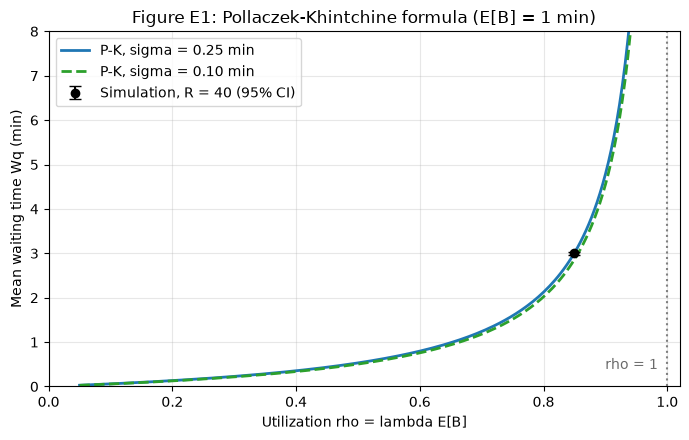

In [69]:
rho_grid = np.linspace(0.05, 0.95, 200)
fig, ax = plt.subplots(figsize=(7, 4.5))
for sig, st in [(0.25, {"color": "C0", "linestyle": "-"}), (0.10, {"color": "C2", "linestyle": "--"})]:
    ax.plot(rho_grid, rho_grid * (1 + sig**2) / (2 * (1 - rho_grid)), linewidth=2,
            label=f"P-K, sigma = {sig:.2f} min", **st)
ax.errorbar([rho_test], [Wq_sim], yerr=[[Wq_sim - ci_low], [ci_high - Wq_sim]], fmt="o", color="black",
            capsize=4, label=f"Simulation, R = 40 (95% CI)")
ax.axvline(1, color="gray", linestyle=":")
ax.text(0.985, 0.04, "rho = 1", ha="right", va="bottom", transform=ax.get_xaxis_transform(), color="dimgray")
ax.set_xlim(0, 1.02)
ax.set_ylim(0, 8)
ax.set_xlabel("Utilization rho = lambda E[B]")
ax.set_ylabel("Mean waiting time Wq (min)")
ax.set_title("Figure E1: Pollaczek-Khintchine formula (E[B] = 1 min)")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("figE1_pk.png", dpi=200)
plt.show()

### A10. Check that arrival order and completion order differ only slightly here

The main Part 2B results above already use the first 3,000 completions. This optional audit compares them with first-arrival estimates using the same seeds. In a FIFO queue with `c` servers, `n + c - 1` arrivals suffice to determine the first `n` completions exactly. The two averages happen to agree to the displayed precision; this is not an excuse to use arrival order generally.


In [70]:
rows = []
for i, (name, par) in enumerate(scenarios.items()):
    by_arrival, by_completion, swapped = [], [], 0
    for r in range(R):
        seed = 1000 * (i + 1) + r                      # same seeds as Part 2B
        arr, start, dep = simulate_times(lane_rate, par["mean_B"], par["sigma"], par["servers"],
                                         n_passengers_2b + par["servers"] - 1, seed=seed)
        first_done = np.argsort(dep, kind="stable")[:n_passengers_2b]
        by_arrival.append((start - arr)[:n_passengers_2b].mean())
        by_completion.append((start - arr)[first_done].mean())
        swapped += int(np.sum(first_done >= n_passengers_2b))
    rows.append({"Scenario": name, "Mean wait, first 3000 arrivals": np.mean(by_arrival),
                 "Mean wait, first 3000 completions": np.mean(by_completion),
                 "Difference": np.mean(by_completion) - np.mean(by_arrival),
                 "Passengers swapped (all 40 runs)": swapped})
completion_check = pd.DataFrame(rows)
print(completion_check.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

Scenario  Mean wait, first 3000 arrivals  Mean wait, first 3000 completions  Difference  Passengers swapped (all 40 runs)
Baseline                       1142.4909                          1142.4909      0.0000                                 0
Option A                        392.8649                           392.8649      0.0000                                 8
Option B                       1145.5860                          1145.5860      0.0000                                 0
